<a href="https://colab.research.google.com/github/databyhuseyn/MachineLearning/blob/main/Credit_Score_classification_with_full_pipeline_and_hyperparameter_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#!/bin/bash
!curl -L -o credit-score-classification.zip https://www.kaggle.com/api/v1/datasets/download/parisrohan/credit-score-classification && unzip credit-score-classification.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 9739k  100 9739k    0     0  25.7M      0 --:--:-- --:--:-- --:--:-- 25.7M
Archive:  credit-score-classification.zip
  inflating: test.csv                
  inflating: train.csv               


In [2]:
!ls

credit-score-classification.zip  sample_data  test.csv	train.csv


In [3]:
import pandas as pd

In [7]:
pd.set_option('display.max_columns', None)

In [8]:
df = pd.read_csv('/content/train.csv')
df.head(1)

/tmp/ipykernel_2904/4254871201.py:1: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/train.csv')


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.82262,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good


In [11]:
df.drop(['ID', 'Customer_ID', 'Name', 'SSN', 'Type_of_Loan'], axis=1, inplace=True)

In [16]:
df['years']=df['Credit_History_Age'].apply(lambda x: str(x).split(' and ')).apply(lambda x: x[0])
df['months']=df['Credit_History_Age'].apply(lambda x: str(x).split(' and ')).apply(lambda x: x[-1])

In [17]:
df.drop(['Credit_History_Age'], axis=1, inplace=True)

In [25]:
df['years'] = pd.to_numeric(df['years'].str.replace('Years', ''), errors='coerce')

In [26]:
df['months'] = pd.to_numeric(df['months'].str.replace('Months', ''), errors='coerce')

In [29]:
df.head(1)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,years,months
0,January,23,Scientist,19114.12,1824.843333,3,4,3,4,3,7,11.27,4.0,_,809.98,26.82262,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good,22.0,1.0


In [41]:
columns_to_change = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly'] # , 'Monthly_Balance'

In [43]:
for column in columns_to_change:
  df[column] = pd.to_numeric(df[column].str.replace('_', ''))

In [51]:
df['Monthly_Balance'] = pd.to_numeric(df['Monthly_Balance'].str.replace('__-333333333333333333333333333__', '').str.replace('_', ''))

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 24 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Month                     100000 non-null  object 
 1   Age                       100000 non-null  int64  
 2   Occupation                100000 non-null  object 
 3   Annual_Income             100000 non-null  float64
 4   Monthly_Inhand_Salary     84998 non-null   float64
 5   Num_Bank_Accounts         100000 non-null  int64  
 6   Num_Credit_Card           100000 non-null  int64  
 7   Interest_Rate             100000 non-null  int64  
 8   Num_of_Loan               100000 non-null  int64  
 9   Delay_from_due_date       100000 non-null  int64  
 10  Num_of_Delayed_Payment    92998 non-null   float64
 11  Changed_Credit_Limit      97909 non-null   float64
 12  Num_Credit_Inquiries      98035 non-null   float64
 13  Credit_Mix                100000 non-null  ob

In [53]:
df.describe()

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,years,months
count,100000.000000,1.000000e+05,84998.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,92998.000000,97909.000000,98035.000000,100000.000000,100000.000000,100000.000000,95521.000000,97123.000000,90970.000000,90970.000000
mean,110.649700,1.764157e+05,4194.170850,17.091280,22.47443,72.466040,3.009960,21.068780,30.923342,10.389025,27.754251,1426.220376,32.285173,1403.118217,637.412998,402.164483,17.966516,5.597208
std,686.244717,1.429618e+06,3183.686167,117.404834,129.05741,466.422621,62.647879,14.860104,226.031892,6.789496,193.177339,1155.129026,5.116875,8306.041270,2043.319327,213.644217,8.319862,3.449988
min,-500.000000,7.005930e+03,303.645417,-1.000000,0.00000,1.000000,-100.000000,-5.000000,-3.000000,-6.490000,0.000000,0.230000,20.000000,0.000000,0.000000,0.007760,0.000000,0.000000
25%,24.000000,1.945750e+04,1625.568229,3.000000,4.00000,8.000000,1.000000,10.000000,9.000000,5.320000,3.000000,566.072500,28.052567,30.306660,74.534002,269.998334,12.000000,3.000000
50%,33.000000,3.757861e+04,3093.745000,6.000000,5.00000,13.000000,3.000000,18.000000,14.000000,9.400000,6.000000,1166.155000,32.305784,69.249473,135.925682,336.472111,18.000000,5.000000
75%,42.000000,7.279092e+04,5957.448333,7.000000,7.00000,20.000000,5.000000,28.000000,18.000000,14.870000,9.000000,1945.962500,36.496663,161.224249,265.731733,469.652004,25.000000,9.000000
max,8698.000000,2.419806e+07,15204.633333,1798.000000,1499.00000,5797.000000,1496.000000,67.000000,4397.000000,36.970000,2597.000000,4998.070000,50.000000,82331.000000,10000.000000,1602.040519,33.000000,11.000000


In [73]:
df['Age'].loc[df['Age'] < 18] = None
df['Age'].loc[df['Age'] > 56] = None

df['Num_Bank_Accounts'].loc[df['Num_Bank_Accounts'] < 0] = None
df['Num_Bank_Accounts'].loc[df['Num_Bank_Accounts'] > 10] = None

df['Num_Credit_Card'].loc[df['Num_Credit_Card'] > 10] = None

df['Interest_Rate'].loc[df['Interest_Rate'] > 34] = None

df['Num_of_Loan'].loc[df['Num_of_Loan'] < 0] = None
df['Num_of_Loan'].loc[df['Num_of_Loan'] > 9] = None

df['Num_of_Delayed_Payment'].loc[df['Num_of_Delayed_Payment'] > 9] = None

df['Num_Credit_Inquiries'].loc[df['Num_Credit_Inquiries'] > 9] = None

/tmp/ipykernel_2904/1810506782.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['Age'].loc[df['Age'] < 18] = None
/tmp/ipykernel_2904/1810506782.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Dat

In [74]:
df.isna().sum()

,0
Month,0
Age,8487
Occupation,0
Annual_Income,0
Monthly_Inhand_Salary,15002
Num_Bank_Accounts,1345
Num_Credit_Card,2307
Interest_Rate,2034
Num_of_Loan,4348
Delay_from_due_date,0


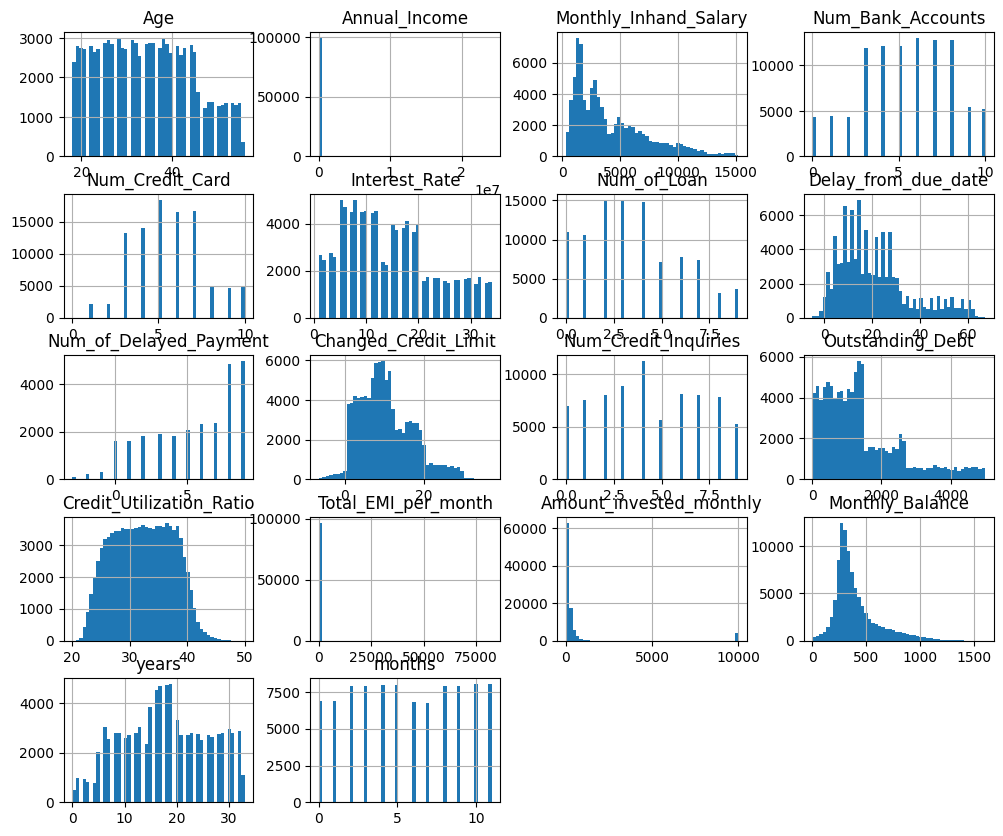

In [76]:
df.hist(bins=50, figsize=(12, 10));

In [77]:
X = df.drop(['Credit_Score'], axis=1)
y = df['Credit_Score'].copy()

In [78]:
from sklearn.model_selection import train_test_split

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [80]:
num_features = X_train.select_dtypes(include='number').columns
cat_features = X_train.select_dtypes(exclude='number').columns

In [81]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

In [84]:
num_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

cat_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

transformer = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
],remainder='passthrough')

model = RandomForestClassifier()

full_pipeline = Pipeline([
    ('preprocessing', transformer),
    ('estimator', model)
])

In [85]:
full_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  Index(['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Paymen...
       'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance',
       'years', 'months'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Month', 'Occupation', 'Credit_Mix', 'Payment_of_Min_Amount',
       'Payment_Behaviour'],
      dtype='object'))])),
                ('estimator', RandomForestClassifier())])

In [86]:
print(f'Train score: {full_pipeline.score(X_train, y_train)}\nTest score: {full_pipeline.score(X_test, y_test)}')

Train score: 1.0
Test score: 0.7761


In [87]:
from sklearn.model_selection import GridSearchCV   # RandomizedSearchCV

In [92]:
param_grid = {
    'estimator__n_estimators': range(60, 121, 20),
    'estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'estimator__max_depth': [10, 20, 50, None]
}

gscv = GridSearchCV(full_pipeline, param_grid, cv=3)


In [ ]:
gscv.fit(X_train, y_train)

In [ ]:
gscv.best_params_

In [ ]:
gscv.best_score_

In [ ]:
gscv.best_estimator_

In [ ]:
gscv.best_estimator_.fit(X_train, y_train)

In [ ]:
print(f'Train score: {gscv.best_estimator_.score(X_train, y_train)}\nTest score: {gscv.best_estimator_.score(X_test, y_test)}')